# 02 · Audit, clean, split, and the analysis
**Owner: P1** (audit, cleaning, split) · **P2** (sections 4-A1..A4 analysis) · Status: `[ ]`

Rules: decisions and plots use **May (train) only**. June/July exist only to be cleaned with May's parameters.

In [1]:
import sys; sys.path.insert(0, "..")          # repo root, so `import src...` works
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.config import TARGET
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 140)

from src.data import load_raw, split_by_month
from src.clean import build_datasets, DEFAULTS
from src.features import add_features, DIST_BINS

## 1. Audit the raw data (May only)

In [2]:
raw = load_raw()
splits, n_out = split_by_month(raw)
may = splits["train"]
print({k: len(v) for k, v in splits.items()}, "| pickups outside May-July 2026:", n_out)
dur = (may.tpep_dropoff_datetime - may.tpep_pickup_datetime).dt.total_seconds() / 60
audit = pd.Series({
    "fare <= 0": (may.fare_amount <= 0).mean(),
    "distance == 0": (may.trip_distance == 0).mean(),
    "distance > 50 mi": (may.trip_distance > 50).mean(),
    "duration <= 0 min": (dur <= 0).mean(),
    "duration > 3 h": (dur > 180).mean(),
    "flex fare (payment 0)": (may.payment_type == 0).mean(),
    "rate code != 1": (may.RatecodeID.ne(1)).mean(),
    "unknown zones 264/265": may.PULocationID.isin([264, 265]).add(may.DOLocationID.isin([264, 265])).gt(0).mean(),
    "missing passenger_count": may.passenger_count.isna().mean(),
}).round(4).to_frame("share of May rows")
audit

{'train': 199999, 'val': 200001, 'test': 199998} | pickups outside May-July 2026: 2


,share of May rows
fare <= 0,0.0042
distance == 0,0.0277
distance > 50 mi,0.0002
duration <= 0 min,0.0132
duration > 3 h,0.0003
flex fare (payment 0),0.2330
rate code != 1,0.3042
unknown zones 264/265,0.0064
missing passenger_count,0.2330


### Findings table (fix / flag / drop)
One row per problem. This is a graded artifact: `how found` should point at a cell above.

| Problem | How found | Rows | Decision | Rationale |
|---|---|---|---|---|
| | | | | |

### Are flex fares comparable to metered fares? (decides cleaning step 2)
Compare fare-per-mile distributions for payment type 0 vs card/cash, in the same distance bands. If they look like the same process you may *keep* them (set `drop_flex=False`); if not, drop and say why.

In [3]:
t = may[(may.trip_distance > 0) & (may.fare_amount > 0)].copy()
t["fpm"] = t.fare_amount / t.trip_distance
t["band"] = pd.cut(t.trip_distance, DIST_BINS)
t["flex"] = t.payment_type.eq(0)
t.groupby(["band", "flex"], observed=True)["fpm"].describe()[["count", "25%", "50%", "75%"]].unstack("flex")

count                25%                   50%                   75%           
flex            False    True      False      True       False      True       False      True 
band                                                                                           
(0.0, 1.0]    37700.0   4424.0  9.247312  11.676731  10.943396  17.461350  14.086108  42.314044
(1.0, 2.0]    48464.0   9544.0  7.133333   7.958115   8.190476  10.200000   9.743590  13.245945
(2.0, 5.0]    37750.0  18000.0  5.736041   5.906809   6.553288   7.328788   7.687075   9.250813
(5.0, 10.0]   14253.0   8798.0  4.308588   4.050000   4.771372   4.866288   5.373609   5.927219
(10.0, 20.0]  11286.0   1898.0  3.771552   3.313385   4.046706   3.859927   4.430380   4.454756
(20.0, inf]    1451.0    161.0  3.044678   2.328900   3.431373   3.301887   3.931069   3.913432

## 2. Split and clean (params fitted on May, reused on June/July)

In [4]:
D = build_datasets(raw)                      # same cleaning code that the pipeline notebooks import
train, val, test = D["train"], D["val"], D["test"]
print(D["n_raw"], D["params"])
display(D["logs"]["train"])
pd.DataFrame({k: v.set_index("step")["pct_of_input"] for k, v in D["logs"].items()})   # do val/test lose similar shares?

{'train': 199999, 'val': 200001, 'test': 199998} {'dist_cap': 24.85494000000006, 'fare_cap': 96.8}


,step,removed,pct_of_input,remaining,why
0,unknown_zones,1271,0.636,198728,zones 264/265 or missing: no usable location
1,flex_fare,46429,23.215,152299,"app-priced, not the meter's time+distance fare..."
2,payment_not_card_cash,1650,0.825,150649,no-charge/dispute/unknown/voided are not real ...
3,non_standard_rate,13493,6.747,137156,flat/negotiated fares follow different rules
4,fare_not_positive,195,0.098,136961,zero/negative fare is not a fare (population d...
5,distance_not_positive,725,0.363,136236,zero distance: no planned route
6,impossible_duration,2729,1.365,133507,corrupt timestamps; used as a validity check only
7,above_caps,165,0.083,133342,above May 0.999 quantile caps {'dist_cap': 24....


,train,val,test
step,,,
unknown_zones,0.636,0.723,0.766
flex_fare,23.215,26.308,27.379
payment_not_card_cash,0.825,0.848,0.862
non_standard_rate,6.747,3.458,5.022
fare_not_positive,0.098,0.110,0.123
distance_not_positive,0.363,0.388,0.380
impossible_duration,1.365,1.352,1.200
above_caps,0.083,0.082,0.089


**Check:** the removed-% should look similar across months (cleaning not drifting). If July loses a very different share, find out why *before* modelling. Paste May's log into `PROBLEM.md`.

## 3. Sanity check on the cleaned May data

In [5]:
display(train[["trip_distance", TARGET]].describe().T)
assert (train[TARGET] > 0).all() and (train.trip_distance > 0).all()

,count,mean,std,min,25%,50%,75%,max
trip_distance,133342.0,2.556204,2.798224,0.01,0.98,1.6,2.8,24.85
fare_amount,133342.0,16.880653,11.915061,3.00,9.30,13.5,20.5,96.80


## 4. The analysis (May / train only)
### A1 · Fare vs distance: how much does distance alone explain?

fare ~ distance: start = $6.67, per mile = $3.99, R^2 = 0.880


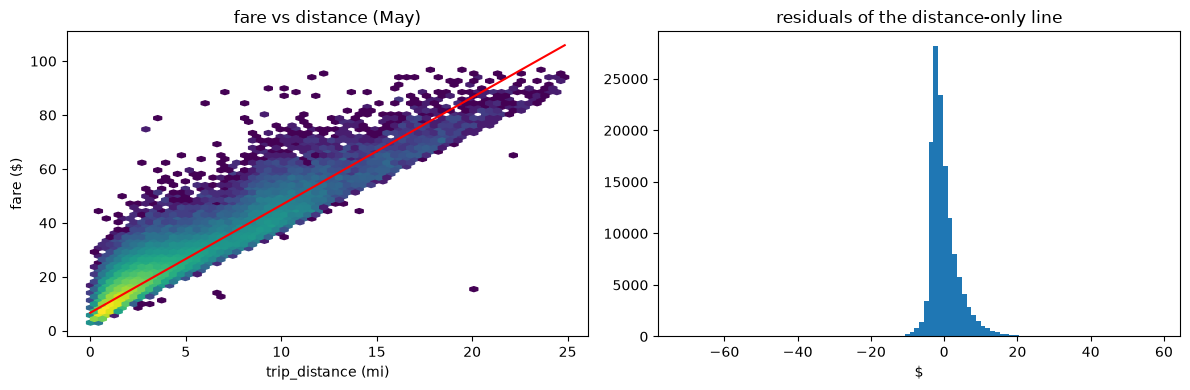

In [6]:
from sklearn.linear_model import LinearRegression
X, y = train[["trip_distance"]], train[TARGET]
lr = LinearRegression().fit(X, y)
print(f"fare ~ distance: start = ${lr.intercept_:.2f}, per mile = ${lr.coef_[0]:.2f}, R^2 = {lr.score(X, y):.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hexbin(train.trip_distance, train[TARGET], gridsize=60, bins="log", mincnt=1)
xs = np.linspace(0, train.trip_distance.max(), 50); ax[0].plot(xs, lr.predict(pd.DataFrame({"trip_distance": xs})), "r-")
ax[0].set(xlabel="trip_distance (mi)", ylabel="fare ($)", title="fare vs distance (May)")
ax[1].hist(train[TARGET] - lr.predict(X), bins=100); ax[1].set(title="residuals of the distance-only line", xlabel="$")
plt.tight_layout()

**Write down:** what is the R^2, what do the start charge and per-mile price look like, where is the line visibly wrong (look at the left edge and the top)?

### A2 · Fare per mile by hour and borough
Fare-per-mile is inflated by the fixed charge on short trips, so **stratify by distance band** or you will "discover" that short trips are expensive.

,size,median
pickup_borough,,
Bronx,48,5.76
Brooklyn,537,6.21
Manhattan,124533,8.12
Queens,8223,4.42
Staten Island,1,5.31


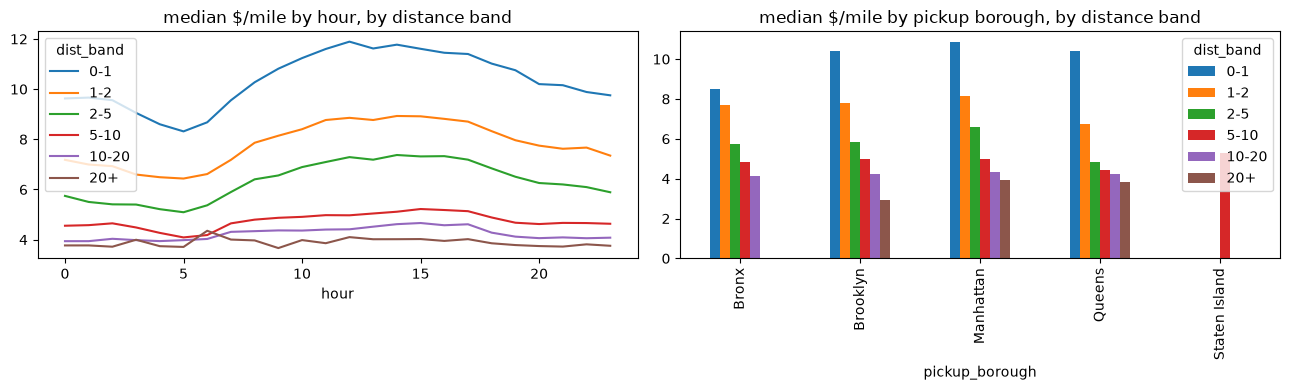

In [7]:
f = add_features(train)
f["fpm"] = f[TARGET] / f.trip_distance
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
f.pivot_table(index="hour", columns="dist_band", values="fpm", aggfunc="median", observed=True).plot(ax=ax[0], title="median $/mile by hour, by distance band")
f.pivot_table(index="pickup_borough", columns="dist_band", values="fpm", aggfunc="median", observed=True).plot(kind="bar", ax=ax[1], title="median $/mile by pickup borough, by distance band")
plt.tight_layout()
f.groupby("pickup_borough")["fpm"].agg(["size", "median"]).round(2)

**Write down:** when and where is a mile more expensive, and *why*? (Hint: the meter also bills time in slow traffic; you cannot see duration at booking. Check the official TLC page for the surcharge and time rules.)

### A3 · Airport trips and very short trips: same pattern?

fpm            res       
                size median    size median
airport_trip                              
0             124486   8.12  124486  -0.93
1               8856   4.38    8856  -3.43

,size,mean,median
dist_band,,,
0-1,35797,-1.41,-2.13
1-2,46607,0.09,-0.78
2-5,34931,1.54,0.52
5-10,11348,0.18,-0.94
10-20,4503,-1.83,-3.31
20+,156,-8.61,-9.29


<Axes: title={'center': 'airport trips: fare vs distance'}, xlabel='trip_distance', ylabel='fare_amount'>

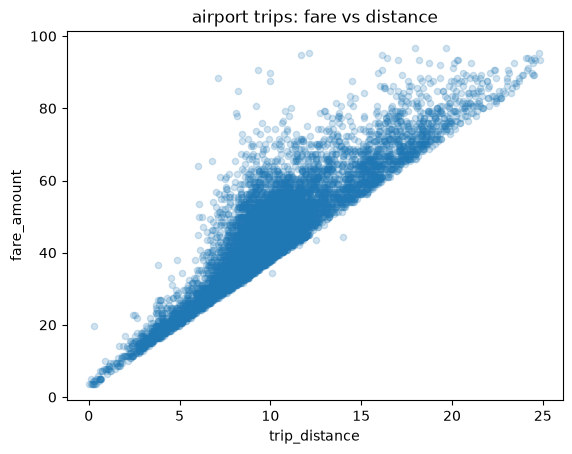

In [8]:
f["res"] = f[TARGET] - lr.predict(f[["trip_distance"]])
display(f.groupby("airport_trip")[["fpm", "res"]].agg(["size", "median"]).round(2))
display(f.groupby("dist_band", observed=True)["res"].agg(["size", "mean", "median"]).round(2))
f[f.airport_trip == 1].plot.scatter("trip_distance", TARGET, alpha=.2, title="airport trips: fare vs distance")

### A4 · The strangest fares (on RAW May, before cleaning): explain or remove, in writing

In [9]:
m = may.assign(fpm=may.fare_amount / may.trip_distance.replace(0, np.nan))
cols = ["tpep_pickup_datetime", "trip_distance", "fare_amount", "total_amount", "payment_type", "RatecodeID", "PULocationID", "DOLocationID"]
print("highest fare for short trips (<1 mi):"); display(m[m.trip_distance.between(0.01, 1)].nlargest(15, "fare_amount")[cols])
print("zero / negative fares by payment type:"); display(m[m.fare_amount <= 0].payment_type.value_counts(dropna=False))
print("highest fare per mile:"); display(m.nlargest(15, "fpm")[cols + ["fpm"]])

highest fare for short trips (<1 mi):


,tpep_pickup_datetime,trip_distance,fare_amount,total_amount,payment_type,RatecodeID,PULocationID,DOLocationID
145029,2026-05-22 17:14:19,0.06,320.00,385.20,1,5.0,132,132
94067,2026-05-15 12:04:36,0.04,300.00,301.00,1,5.0,219,132
105974,2026-05-16 21:19:31,0.04,300.00,301.00,1,5.0,132,132
117612,2026-05-18 17:31:39,0.03,177.73,182.48,0,NaN,230,265
102329,2026-05-16 12:53:52,0.14,165.52,170.27,0,NaN,100,100
19467,2026-05-03 23:37:14,0.01,150.00,158.00,1,5.0,138,138
137384,2026-05-21 13:49:30,0.03,150.00,153.00,1,5.0,132,132
54994,2026-05-09 16:10:48,0.31,148.00,178.80,1,5.0,265,265
20809,2026-05-04 10:35:59,0.13,125.25,151.50,1,5.0,132,219
112063,2026-05-17 18:18:09,0.18,125.00,151.20,1,5.0,265,265


zero / negative fares by payment type:


payment_type
4    445
2    215
3     97
0     62
1     13
Name: count, dtype: int64

highest fare per mile:


,tpep_pickup_datetime,trip_distance,fare_amount,total_amount,payment_type,RatecodeID,PULocationID,DOLocationID,fpm
19467,2026-05-03 23:37:14,0.01,150.00,158.00,1,5.0,138,138,15000.0
4575,2026-05-01 18:39:23,0.01,123.87,136.08,0,NaN,161,55,12387.0
79927,2026-05-13 14:55:16,0.01,114.56,118.06,1,5.0,230,230,11456.0
3695,2026-05-01 16:49:12,0.01,113.94,118.69,0,NaN,166,97,11394.0
41445,2026-05-07 16:16:43,0.01,103.01,134.36,0,NaN,151,132,10301.0
21325,2026-05-04 12:28:54,0.01,99.00,100.00,1,5.0,197,197,9900.0
178280,2026-05-28 19:01:14,0.01,97.00,101.25,1,5.0,161,161,9700.0
55511,2026-05-09 17:30:24,0.01,95.00,117.20,1,5.0,132,132,9500.0
110725,2026-05-17 14:50:36,0.01,93.50,113.40,1,5.0,132,132,9350.0
96060,2026-05-15 16:56:31,0.01,92.00,111.60,1,5.0,226,226,9200.0


**Categorise** the oddities (data entry, long wait, flat fare, refund/void, ...) and tie each category to a cleaning step. Anything you keep that looks wrong needs a sentence of justification.

## 5. Decisions summary (feeds PROBLEM.md)
- ...